# Homework 3 (Hard deadline: 6.12.2026 22:00)




## AI can be used, but must be reported.
## AI shall not be used to complete the whole assignment.

## Learning Objectives
- Read and inspect raw data

- Clean and prepare data

- Descriptive and summary statistics

- Scale numerical variables

- Create visualizations

- Draw conclusions from data

- Typical data management process



## Typical Data Management Process
1. Acquire / read the data

2. Inspect and understand the data

3. Assess data quality

4. Clean the data

5. Transform and prepare the data

6. Explore and analyze the data

7. Visualize the data

8. Interpret results

9. Communicate findings

10. Store and share the prepared data

While doing this homework, think, which step of the data management process the task is related to.

## Scenario

You work for a taxi company.

The management team wants to better understand:
- trip durations
- average fares and distances
- number of trips

Your task is to clean the data, analyze it, visualize key findings, and report your conclusions.

## General Instructions
- Use the sns `taxis` dataset
- Read it first in Pandas DataFrame and then complete the tasks.
- Remember to comment your code, good policy is to have at least a short comment in every code cell.
- Add code cells when necessary.
- Good policy is to do one or few related operations in one code cell (e.g. read csv and check how it looks like in one cell and then e.g. df.info() in another etc.).
- Max points: 19

## Task 1: Load and Inspect the Data (2 points)

- Load the `taxis` dataset using Seaborn.
- Display head and tail.
- Investigate shape, columns, dtypes and info.
- Calculate missing values using isna and sum.
- Find the feature containing most missing values.
- Identify categorical, numerical and datetype variables.
- Answer the questions.

**Assessment guide for task 1:**
- 0 points: not done or less than half done
- 1 point: not completely done but more than half done
- 2 points: completely done

In [2]:
# Take necessary libraries in use
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Read data (taxis.csv) to a Pandas DataFrame whose name is df.
df = sns.load_dataset('taxis') # create a data frame named 'df' by loading from dataset of sns.
df.info()# Checking the general information of the df

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


In [4]:
df.head()# Checking that the data is read correctly

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [5]:
# displaying tail:
df.tail()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn
6432,2019-03-13 19:31:22,2019-03-13 19:48:02,1,3.85,15.0,3.36,0.0,20.16,green,credit card,Boerum Hill,Windsor Terrace,Brooklyn,Brooklyn


#### Investigate shape, columns, dtypes and info.

In [6]:
# Investigate shape
df.shape # number of rows, number of columns

(6433, 14)

In [7]:
# Investigate columns
df.columns # return names of columns (variables) of the df

Index(['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls',
       'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone',
       'pickup_borough', 'dropoff_borough'],
      dtype='str')

In [8]:
# Investigate data types of all variables:
df.dtypes

pickup             datetime64[us]
dropoff            datetime64[us]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                         str
payment                       str
pickup_zone                   str
dropoff_zone                  str
pickup_borough                str
dropoff_borough               str
dtype: object

#### Calculate missing values using isna and sum.

In [9]:
df.isna() # check if there is any missing value for each data cell (True - False)

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,False,False,False,False,False,False,False,False,False,False,False,False,False,False
6429,False,False,False,False,False,False,False,False,False,False,False,False,False,False
6430,False,False,False,False,False,False,False,False,False,False,False,False,False,False
6431,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [10]:
df.isna().sum() # check number of missing values for each columns

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [11]:
df.isna().sum().sum() # check number of missing values for the Whole DataFrame (186 NaNs)

np.int64(186)

#### Find the feature containing most missing values.

In [12]:
missing = df.isna().sum() # assign the dataframe to a variable 'missing'
list_of_missing = [] # make an empty list
for i in df.columns:
    if missing[i] == missing.max(): # find the index with max value
        list_of_missing.append(i)  # add all the same max indices (which are also features) to the list
print('Number of features with same most missing values:', len(list_of_missing))
list_of_missing # print the list of feature with most missing values

Number of features with same most missing values: 2


['dropoff_zone', 'dropoff_borough']

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


#### Identify categorical, numerical and datetype variables.

### Task 1 questions
Answer these questions:
1. How many rows and columns are in the dataset?
* Rows = 6433; columns = 14

2. Which variables contain missing values?
* payment:            44
* pickup_zone:        26
* dropoff_zone:       45
* pickup_borough:     26
* dropoff_borough:    45 

3. Which variable has the most missing values?
* 'dropoff_zone' and 'dropoff_borough'

4. Which variables are categorical?
* color            | str           
* payment          | str           
* pickup_zone      | str           
* dropoff_zone     | str           
* pickup_borough   | str           
* dropoff_borough  | str 

5. Which variables are numerical?
* passengers       |  int64         
* distance         |   float64
* fare             |   float64       
* tip              |   float64       
* tolls            |   float64       
* total            |   float64   

6. Which variables appear to be datetime variables?
* pickup           |   datetime64[us]
* dropoff          |   datetime64[us]

## Task 2: Data Cleaning (2 points)

- Check duplicates using *duplicated* and *sum*.
- Drop rows with missing values and check what happened.

**Assessment guide for task 2:**
- 0 points: not done or less than half done
- 1 point: not completely done but more than half done
- 2 points: completely done

#### Check duplicates using *duplicated* and *sum*.

In [ ]:
df.duplicated() # check each row/entry

0       False
1       False
2       False
3       False
4       False
        ...  
6428    False
6429    False
6430    False
6431    False
6432    False
Length: 6433, dtype: bool

In [ ]:
df.duplicated().sum() # check total number of duplicated rows
# --> no duplicated entry

np.int64(0)

#### Drop rows with missing values and check what happened.

In [ ]:
df=df.dropna() # drop all missing values
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [27]:
df.info()

<class 'pandas.DataFrame'>
Index: 6341 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6341 non-null   datetime64[us]
 1   dropoff          6341 non-null   datetime64[us]
 2   passengers       6341 non-null   int64         
 3   distance         6341 non-null   float64       
 4   fare             6341 non-null   float64       
 5   tip              6341 non-null   float64       
 6   tolls            6341 non-null   float64       
 7   total            6341 non-null   float64       
 8   color            6341 non-null   str           
 9   payment          6341 non-null   str           
 10  pickup_zone      6341 non-null   str           
 11  dropoff_zone     6341 non-null   str           
 12  pickup_borough   6341 non-null   str           
 13  dropoff_borough  6341 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)
memor

In [31]:
df.isna().sum().sum() # check if there is any missing value left.

np.int64(0)

## Task 3: Descriptive Statistics (2 points)

- Use describe() and investigate distance and fare. Determine mean, median, minimum, maximum and standard deviation.

- Check if the fare appears normally distributed and compare its mean and median.

  **Hint**: to check normality, use a plot (find out, which plot).

- Answer the questions.

**Assessment guide for task 1:**
- 0 points: not done or less than half done
- 1 point: not completely done but more than half done
- 2 points: completely done

#### Use describe() and investigate distance and fare. Determine mean, median, minimum, maximum and standard deviation.

In [ ]:
df[['distance','fare']].describe() # select only 'distance' and 'fare'

,distance,fare
count,6341.000000,6341.000000
mean,2.997707,12.887931
std,3.719775,10.722249
min,0.000000,1.000000
25%,0.990000,6.500000
50%,1.650000,9.500000
75%,3.200000,15.000000
max,36.700000,150.000000


#### Check if the fare appears normally distributed and compare its mean and median.

  **Hint**: to check normality, use a plot (find out, which plot).

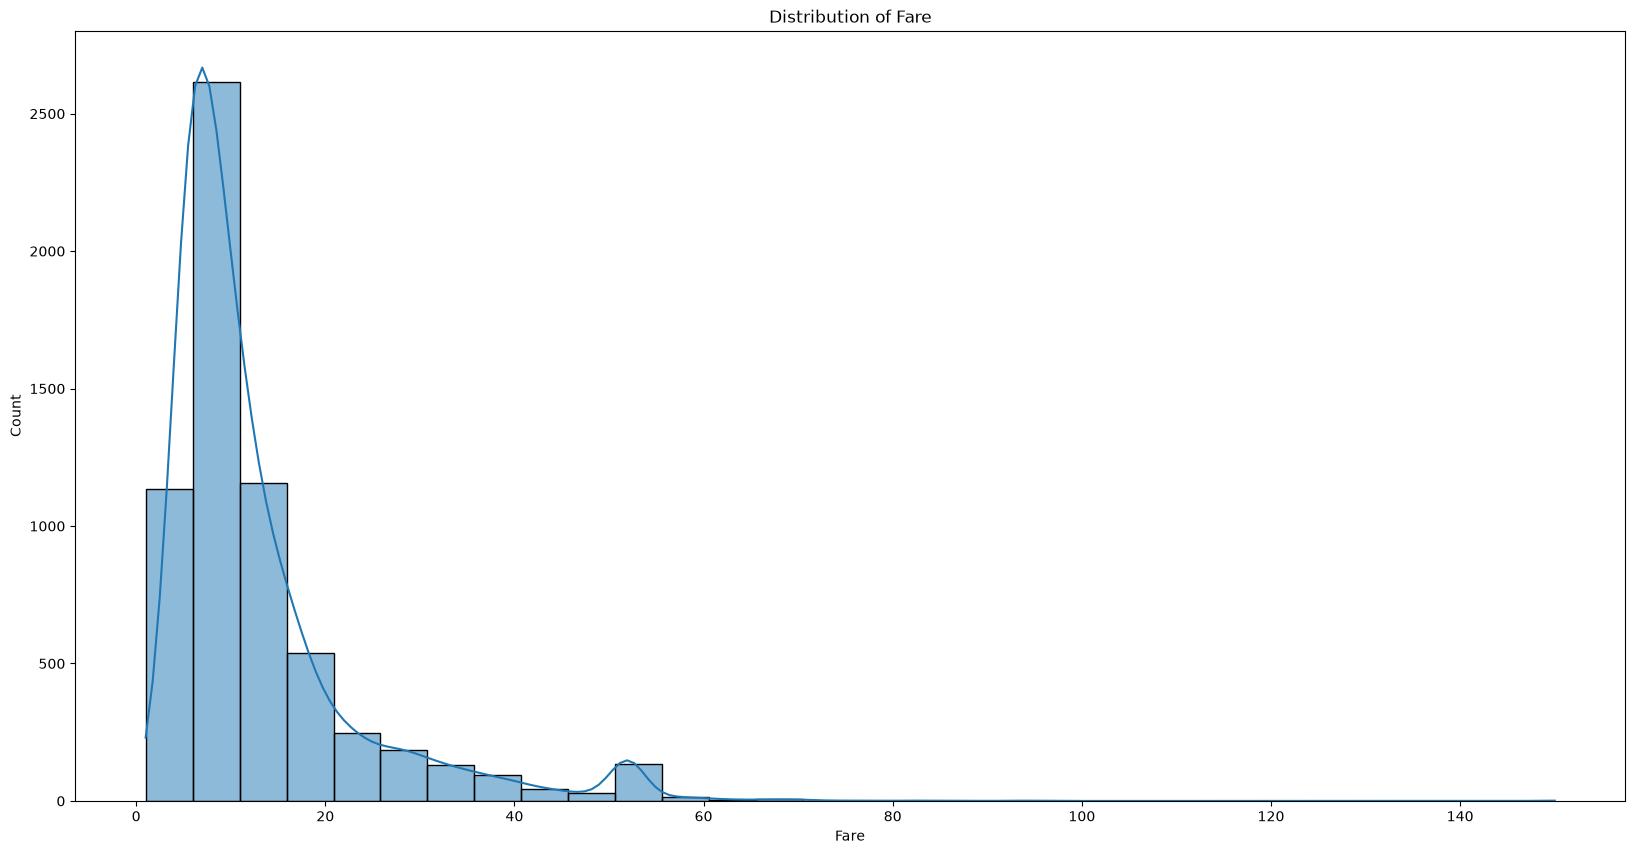

In [39]:
plt.figure(figsize=(20, 10))
sns.histplot(df['fare'], kde=True, bins=30)
plt.title('Distribution of Fare')
plt.xlabel('Fare')
plt.ylabel('Count')
plt.show()

<Axes: xlabel='fare'>

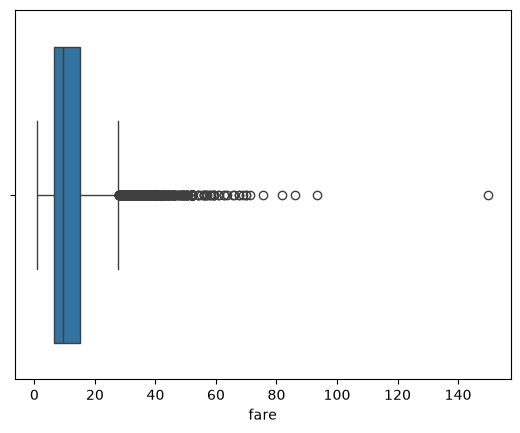

In [40]:
sns.boxplot(x=df['fare'])

### Task 3 questions
Answer these questions:
1. Does the fare look normally distributed? Why/why not?

2. How do the mean and median variables comparison tell this?

3. Are there outliers in the fare? Or anything else noteworthy?

  

## Task 4: Summaries (2 points)

- Calculate first the average trip duration in minutes and add that to the dataframe.

- Create a summary table showing:
  - average fare, average distance, average trip duration (in minutes), and  number of trips for each pickup borough.

- Answer the qustions.

**Assessment guide for task 4:**
- 0 points: not done or less than half done
- 1 point: not completely done but more than half done
- 2 points: completely done


In [15]:
# YOUR CODE HERE; ADD MORE CODE CELLS WHEN NEEDED

### Task 4 questions
Answer these questions:
1. Which borough has the highest average fare?

2. Which borough has the longest trips?

3. Which borough generates the most trips?


## Task 5: Scaling Numerical Data (2 points)

- Use StandardScaler to scale fare, distance and trip_duration_min.
- Create age_scaled, fare_scaled and trip_duration_min_scaled.
- Verify means and standard deviations after scaling.
- Answer the question.

**Assessment guide for task 5:**
- 0 points: not done or less than half done
- 1 point: not completely done but more than half done
- 2 points: completely done

In [16]:
# YOUR CODE HERE; ADD MORE CODE CELLS WHEN NEEDED

### Task 5 question
Answer this question:
1. Why is the mean not (necessarily) precisely 0 and standard deviation not precisely 1?



## Task 6 Linear Regression (5 points)
- Use the `scikit-learn` to predict the taxi `fare` using two independent variables: `distance` and `trip_duration_min`.

- Get the intercept and also r2_score.

- Compare these two models:
  1. **Unscaled taxi data**
  2. **Scaled taxi data** (to compare feature importance/coefficients directly)

- Compare their intercepts and also r2_score.

- Plot both with the regression line.
- Answer the questions.

**Hints**:
1. Check out week 41 lecture slides and see how to do linear regression and get the intercept. Then find out how to get the r2_score.
2. Use these:
  - from sklearn.linear_model import LinearRegression
  - from sklearn.metrics import r2_score
3. Use these (in unscaled data, figure out the scaled data versions yourself):
  - X_unscaled = taxis_cleaned[["distance", "trip_duration_min"]]
  - y_unscaled = taxis_cleaned["fare"]


**Assessment guide for task 6:**
- 2 points from unscaled data model and plot (1 point from nice try; 0 points from mostly or totally missing)
- 2 points from scaled data model and plot (1 point from nice try; 0 points from mostly or totally missing)
- 1 point form answering the questions

In [17]:
# YOUR CODE HERE; ADD MORE CODE CELLS WHEN NEEDED

### Task 6 questions
Answer these questions:
1. Are the r2_score of the two models same or different? Why?

2. What is the intercept of the model using scaled data? Why?

3. When you compare the unscaled and scaled model's plots, what do you notice? How should they be interpreted?


## Part 7: Data Visualization (4 points)

- Create and interpret these four visualizations:
  1. Scatterplot distance vs. fare
  2. Distance distribution
  3. Trips by hour
  4. Average fare by borough

- Use propriate titles and axis names
- Interprete the plots (briefly).

**Assessment guide for task 7:**
- 1 point per plot + interpretation if well done according to instructions
- 0.5 points per plot: nice try
- 0 points: mostly or completely not done


In [18]:
# YOUR CODE HERE; ADD MORE CODE CELLS WHEN NEEDED

### Part 7 plots' interpretations here
  1. Scatterplot distance vs. fare:

  2. Distance distribution:
  
  3. Trips by hour:
  
  4. Average fare by borough:

## Task: AI statement (mandatory, missing AI statement (if AI used) is considered fraud)

- Describe here, how did you use AI in this assignment
- Describe also, if you did not use AI in this assignment


## Task: Self assessment (mandatory, missing self assessment causes -1 point)

- Check the task specific assessment instructions.
- How many points would you give yourself? ANSWER HERE:
- If missing points, why are they missing and which task is missing points? ANSWER HERE:


## Homework return (mandatory)

- File > Save and Export Notebook As > HTML
- Then take a look the produced HTML that it looks ok and readable (= it looks like this Jupyter notebook looks, so no html source code etc. shall be visible)
- Return to Itslearning, only the html document is returned, *not* the .ipynb
